In [2]:
import pandas as pd

# Load Data

In [3]:
# data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\tonghopdata.csv')

data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\GSE183635_TEP_Count_Matrix.csv')
# name_gene =  pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\183635\Human_CH38p13annot.csv', low_memory=False    )


In [4]:
data

,Unnamed: 0,1-Vumc-HD-101-TR922,2-Vumc-HD-103-TR923,3-Vumc-HD-108-TR924,4-Vumc-HD-127-TR925,5-Vumc-HD-130-TR926,6-Vumc-HD-142-TR927,7-Vumc-HD-143-TR928,8-Vumc-HD-144-TR929,9-Vumc-HD-145-TR930,...,countMatrix.3502-NKI-4854-SARC-TR3080,countMatrix.3503-NKI-4707-SARC-TR3079,countMatrix.3504-NKI-4941-SARC-TR3084,countMatrix.3507-NKI-6348-SARC-TR3134,countMatrix.3508-NKI-5275-SARC-TR3099,countMatrix.3512-NKI-5148-SARC-TR3129,countMatrix.320-10,countMatrix.327-34,countMatrix.376-P-PH-001-013-TR1400,countMatrix.506-NKI-NSCLC-107-270
0,ENSG00000000419,5,79,58,128,93,12,0,0,18,...,3,0,1,2,9,16,22,21,0,1
1,ENSG00000000460,8,10,21,14,6,8,25,42,5,...,0,3,0,2,63,3,3,0,1,0
2,ENSG00000000938,24,336,334,59,120,22,31,13,19,...,8,45,1,7,163,90,46,75,14,8
3,ENSG00000001036,38,46,15,36,25,43,27,27,59,...,1,3,4,15,3,6,10,8,3,0
4,ENSG00000001461,72,17,11,9,18,28,5,6,49,...,1,1,0,0,12,2,6,6,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5435,ENSG00000271043,349,133,99,87,171,260,232,204,188,...,0,0,0,5,0,2,18,31,22,23
5436,ENSG00000272053,980,658,294,265,818,2066,1579,1161,2003,...,18,17,17,107,41,52,78,203,12,16
5437,ENSG00000272168,51,20,11,31,65,49,56,25,131,...,0,0,0,26,0,1,15,6,10,0
5438,ENSG00000272369,29,41,24,3,51,33,26,52,35,...,0,3,1,8,2,1,0,3,2,1


In [ ]:
import numpy as np

# Minimal TMM normalization adapted from edgeR logic
# Returns CPM and factors scaled so geometric mean of factors is 1.
def compute_tmm_cpm(counts_df, trim_M=0.3, trim_A=0.05, ref_sample=None):
    counts = counts_df.copy()
    lib_sizes = counts.sum(axis=0)

    # Pick reference sample: closest library size to median if none provided
    if ref_sample is None:
        ref_sample = (lib_sizes - lib_sizes.median()).abs().idxmin()
    ref_counts = counts[ref_sample]
    lib_ref = lib_sizes[ref_sample]

    factors = {}

    def tmm_factor(test_counts, lib_test):
        mask = (test_counts > 0) & (ref_counts > 0)
        if mask.sum() == 0:
            return 1.0

        test = test_counts[mask]
        ref = ref_counts[mask]

        logR = np.log2((test / lib_test) / (ref / lib_ref))
        logA = 0.5 * np.log2((test / lib_test) * (ref / lib_ref))
        weights = 1.0 / ((1.0 / test) + (1.0 / ref))

        # Trim extremes on M and A
        m_low, m_high = np.quantile(logR, [trim_M / 2, 1 - trim_M / 2])
        a_low, a_high = np.quantile(logA, [trim_A / 2, 1 - trim_A / 2])
        keep = (logR >= m_low) & (logR <= m_high) & (logA >= a_low) & (logA <= a_high)

        if keep.sum() == 0:
            return 1.0

        weighted_M = np.average(logR[keep], weights=weights[keep])
        return 2 ** weighted_M

    for col in counts.columns:
        factors[col] = tmm_factor(counts[col], lib_sizes[col])

    factors = pd.Series(factors)
    factors = factors / np.exp(np.log(factors).mean())  # rescale to geometric mean 1
    effective_lib_sizes = lib_sizes * factors

    cpm = counts.divide(effective_lib_sizes, axis=1) * 1_000_000
    return cpm, factors, effective_lib_sizes

In [ ]:
# Apply TMM normalization → CPM → log2(CPM+1)
count_cols = data.columns.drop('Unnamed: 0')
counts_numeric = data[count_cols].apply(pd.to_numeric, errors='coerce').fillna(0)

# TMM factors trimmed at 30% for M and 5% for A (edgeR defaults)
tmm_cpm, tmm_factors, tmm_libsizes = compute_tmm_cpm(
    counts_numeric,
    trim_M=0.3,
    trim_A=0.05,
)

tmm_log2 = np.log2(tmm_cpm + 1)

# Reattach gene column and use the normalized values for downstream steps
tmm_log2.insert(0, 'Unnamed: 0', data['Unnamed: 0'])
raw_counts = data.copy()
data = tmm_log2

tmm_log2.head()

In [ ]:
data

In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
# Transpose so samples become rows
data_transposed = data.set_index('Unnamed: 0').T
data_transposed

In [ ]:
# data_transposed.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\otherdata can be merged\raw.csv', index=True )

In [ ]:
data_transposed['cancer_type'] = (
    data_transposed['cancer_type']
    .replace('Other/Unknown', 'Asymptomatic_Controls')
)


In [ ]:
data_transposed['cancer_type'].value_counts()

In [ ]:
# Extract the names of the remaining 338
remaining_unknowns = [c for c in data.columns if categorize_tumor_type(c) == 'Other/Unknown']

# Look for patterns

print(pd.Series(remaining_unknowns).head(44))

In [ ]:
data_transposed = data_transposed[
    data_transposed['cancer_type'] != 'Symptomatic_Control'
]

In [ ]:
data_transposed.reset_index(drop=True, inplace=True)


In [ ]:
data_transposed

In [ ]:
# 4) Filter low-expression genes (expressed in ≥10% of samples)
min_samples = len(data_transposed) * 0.01
gene_cols = data_transposed.columns.drop('cancer_type')
expressed_genes_mask = (data_transposed[gene_cols] > 0).sum(axis=0) >= min_samples
data_filtered = data_transposed.loc[:, expressed_genes_mask.index[expressed_genes_mask]]
data_filtered['cancer_type'] = data_transposed['cancer_type']


In [ ]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier


In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
data_normalized = data_filtered.copy()

In [ ]:
# # # 5) MinMax normalize gene expression values
# # data_normalized = data_filtered.copy()

# # Get gene columns (exclude cancer_type)
# gene_cols = data_normalized.columns.drop('cancer_type')

# # Initialize MinMaxScaler
# scaler = MinMaxScaler()

# # Fit and transform only the gene expression columns
# data_normalized[gene_cols] = scaler.fit_transform(data_filtered[gene_cols])

# # Keep cancer_type column
# data_normalized['cancer_type'] = data_filtered['cancer_type']


In [ ]:
data_normalized

In [ ]:
# 6) Split features/labels
X = data_normalized.drop(columns=['cancer_type'])
y = data_normalized['cancer_type']


In [ ]:
X

In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\y_multi_ori.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\normalized_X_multi_log.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv', index=False)

In [ ]:
y = y.apply(lambda x: 1 if x != 'Asymptomatic_Controls' and x != 'Symptomatic_Control' else 0)

In [ ]:
y.value_counts()

In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv', index=False)

# embedded RF with stratify k fold

In [ ]:
import pandas as pd
import numpy as np
import json
import warnings
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Set random state for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
# X = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv", low_memory=False)
# y = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv", low_memory=False).values.ravel()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)

In [ ]:
# X_train.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_train.csv", index= False)
# X_test.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_test.csv", index= False)
# y_train.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\y_train.csv", index= False)
# y_test.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\y_test.csv", index= False)


In [ ]:

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
gene_names = X_train.columns.values

In [ ]:
print("  This may take a few minutes...")

# Parameter grid for RandomForest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5]
}

# RandomForest classifier
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight='balanced',
    n_jobs=-1
)

# Stratified K-Fold
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Grid search
grid_search_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=cv_inner,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=0
)

grid_search_rf.fit(X_scaled, y_train)

# Get feature importances
best_rf = grid_search_rf.best_estimator_
feature_importances = best_rf.feature_importances_

### Ranking all genes by RandomForest importance...

In [ ]:
# Create dataframe with ALL genes and their importance scores
rf_df = pd.DataFrame({
    'gene': gene_names,
    'importance': feature_importances
})
rf_df = rf_df.sort_values('importance', ascending=False)

In [ ]:
rf_df

In [ ]:
rf_df.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\feature_importance.csv', index=False)

In [ ]:
all_features = (
    rf_df.sort_values('importance', ascending=False)
    .head(5440)['gene']
    .tolist()
)

In [ ]:
X_train[all_features]

In [ ]:
X_test[all_features]

In [ ]:
X_train[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_train.csv', index=False)
X_test[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_test.csv', index=False)

In [ ]:
# import matplotlib.pyplot as plt
# plt.figure(figsize=(6, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'], color='blue')
# plt.xlabel('Importance Score')
# plt.ylabel('Feature')
# plt.title('Feature Importance Scores from Random Forest')
# plt.gca().invert_yaxis()  # To display the highest importance at the top
# plt.show()

# Start ML


In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [5]:
X_train = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\ranked rf\X_train_rF_DEG.csv",low_memory = False)
X_test = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\ranked rf\X_test_rF_DEG.csv",low_memory = False)

y_train = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\ranked rf\y_train_rF_DEG.csv",low_memory = False)
y_test = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\ranked rf\y_test_rF_DEG.csv",low_memory = False)

In [7]:
X_train = X_train.iloc[:,:1000]
# 0.00055

In [4]:
X_test = X_test.iloc[:,:1000]

In [43]:
from sklearn.model_selection import StratifiedKFold

In [44]:
from xgboost import XGBClassifier

In [10]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
x_train_sc = scale.fit_transform(X_train)
x_test_sc = scale.transform(X_test)

In [9]:
X_train

,ENSG00000142089,ENSG00000103316,ENSG00000173083,ENSG00000163359,ENSG00000069535,ENSG00000133742,ENSG00000165949,ENSG00000115457,ENSG00000141068,ENSG00000158578,...,ENSG00000244734,ENSG00000206549,ENSG00000013306,ENSG00000101057,ENSG00000147454,ENSG00000143416,ENSG00000239839,ENSG00000115590,ENSG00000206177,ENSG00000012223
0,4.492336,5.705234,5.914831,5.705234,5.507742,0.000000,0.800446,2.940120,5.914831,0.000000,...,7.358964,3.842929,0.000000,0.000000,0.800446,0.000000,1.689262,0.000000,0.000000,0.000000
1,6.737175,4.651462,6.330372,5.099535,5.134133,0.000000,3.511188,5.249079,4.698456,0.000000,...,5.027748,5.200933,4.446492,3.562896,1.805882,0.000000,0.000000,0.000000,0.000000,0.000000
2,4.526937,4.241746,4.132610,2.703426,5.332116,3.412588,1.249971,6.326539,6.824474,1.617087,...,6.997854,1.249971,5.229847,1.249971,1.909479,0.000000,0.000000,0.000000,0.000000,1.249971
3,5.713908,5.482719,1.557255,0.979269,1.557255,2.771632,3.661931,4.714692,7.108281,0.000000,...,8.539547,3.421515,4.419592,3.132861,0.000000,0.000000,0.000000,3.768614,0.000000,0.000000
4,5.945145,5.589250,2.951344,0.000000,0.000000,2.951344,0.000000,6.354317,8.754955,4.406270,...,8.842222,3.854932,5.115760,2.951344,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1610,3.841623,2.234069,4.231281,4.366974,4.417869,3.878429,1.311408,6.379238,7.741561,4.937190,...,11.824729,2.343422,6.615596,0.799848,3.803854,2.713010,3.193787,0.000000,3.134161,3.459745
1611,6.509719,0.000000,4.799330,5.366918,4.465469,5.432442,3.116017,4.696395,6.314997,8.743480,...,14.029905,0.000000,8.173036,0.000000,5.721698,5.555186,0.000000,3.850234,4.799330,5.773189
1612,3.696412,2.441224,5.458806,5.020602,5.850926,0.000000,1.471140,5.399462,7.046123,0.000000,...,6.940790,0.000000,5.487587,0.000000,1.871297,0.000000,0.000000,0.000000,0.000000,0.915486
1613,6.695247,4.990406,4.427959,6.695247,0.000000,0.000000,0.000000,4.990406,9.590021,4.427959,...,9.683013,5.709102,0.000000,0.000000,3.493472,0.000000,5.709102,0.000000,0.000000,5.967533


In [11]:
list_feature = list(X_train.columns)

In [12]:
ranks = []
for i in range(len(list_feature)):
    arr = []
    for j in range(i+1):
        arr.append(list_feature[j])
    ranks.append(arr)

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC

pipe = Pipeline([
    ("smote", SMOTE(k_neighbors=3, random_state=42)),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",  
        probability=True,
        random_state = 42
    ))
])

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [15]:
from sklearn.metrics import confusion_matrix,roc_auc_score
def cfm(y_test,y_pred,y_prob):
    auc = roc_auc_score(y_test,y_prob)
    tn,fp,fn,tp = confusion_matrix(y_test,y_pred).ravel()
    acc = accuracy_score(y_test,y_pred)
    recall = tp/(tp+fn)
    precision = tp/(tp+fp)
    specificity = tn/(tn+fp)
    sensitivity = tp / (tp+fn)
    f1_score = round((2*recall*precision)/(recall+precision),3)
    return np.array([acc,recall,precision,specificity,sensitivity,f1_score,auc])

In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from catboost import CatBoostClassifier

model = KNeighborsClassifier(n_neighbors=5, weights='distance', metric='minkowski', p=2)


params = {
    # 'n_neighbors': [3, 5, 7, 9, 11, 15],
    # 'weights': ['uniform', 'distance'],
    # 'metric': ['euclidean', 'manhattan', 'minkowski'],
    # 'p': [1, 2]
    
    'n_neighbors': [9],
    'weights': ['uniform'],
    'metric': ['euclidean'],
    'p': [1, 2]
}
grid_search = GridSearchCV(estimator=model, param_grid=params, 
                              cv=5, verbose=2, return_train_score=True, n_jobs=-1, pre_dispatch='2*n_jobs')
acc_max_rank = None
acc_max = -np.inf
result = []
best_paramet = None
for i,rank in enumerate(ranks[1:], start=1):
    grid_search.fit(x_train_sc[:,:i+1],y_train['cancer_type'])
    best_parameters = grid_search.best_params_
    best_model = grid_search.best_estimator_
    best_model.fit(x_train_sc[:,:i+1],y_train['cancer_type'])
    y_pred = best_model.predict((x_test_sc[:,:i+1]))
    y_prob = best_model.predict_proba((x_test_sc[:,:i+1]))[:,1]
    acc = accuracy_score(y_test,y_pred)
    evaluate = cfm(y_test,y_pred,y_prob)
    result.append([rank,'%.2f'%(evaluate[0]*100)+'%','%.2f'%(evaluate[1]*100)+'%','%.2f'%(evaluate[2]*100)+'%','%.2f'%(evaluate[3]*100)+'%','%.2f'%(evaluate[4]*100)+'%','%.2f'%(evaluate[5]*100)+'%','%.2f'%(evaluate[6]*100)+'%',best_parameters])

Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates

In [20]:
df_result = pd.DataFrame(result)
df_result.columns = ['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter']
df_result

,Gene,ACC,Recall,Precision,Sp,Sn,f1_Score,AUC,Parameter
0,"[ENSG00000142089, ENSG00000103316]",78.71%,92.66%,83.01%,19.48%,92.66%,87.60%,70.38%,"{'metric': 'euclidean', 'n_neighbors': 9, 'p':..."
1,"[ENSG00000142089, ENSG00000103316, ENSG0000017...",77.97%,91.44%,83.06%,20.78%,91.44%,87.00%,71.43%,"{'metric': 'euclidean', 'n_neighbors': 9, 'p':..."
2,"[ENSG00000142089, ENSG00000103316, ENSG0000017...",81.19%,93.58%,84.76%,28.57%,93.58%,89.00%,78.01%,"{'metric': 'euclidean', 'n_neighbors': 9, 'p':..."
3,"[ENSG00000142089, ENSG00000103316, ENSG0000017...",81.93%,92.97%,85.88%,35.06%,92.97%,89.30%,81.77%,"{'metric': 'euclidean', 'n_neighbors': 9, 'p':..."
4,"[ENSG00000142089, ENSG00000103316, ENSG0000017...",81.68%,93.88%,85.04%,29.87%,93.88%,89.20%,81.13%,"{'metric': 'euclidean', 'n_neighbors': 9, 'p':..."
5,"[ENSG00000142089, ENSG00000103316, ENSG0000017...",84.16%,94.80%,86.83%,38.96%,94.80%,90.60%,82.45%,"{'metric': 'euclidean', 'n_neighbors': 9, 'p':..."
6,"[ENSG00000142089, ENSG00000103316, ENSG0000017...",82.67%,93.27%,86.40%,37.66%,93.27%,89.70%,80.57%,"{'metric': 'euclidean', 'n_neighbors': 9, 'p':..."
7,"[ENSG00000142089, ENSG00000103316, ENSG0000017...",84.65%,95.72%,86.70%,37.66%,95.72%,91.00%,85.31%,"{'metric': 'euclidean', 'n_neighbors': 9, 'p':..."
8,"[ENSG00000142089, ENSG00000103316, ENSG0000017...",82.92%,94.19%,86.03%,35.06%,94.19%,89.90%,84.47%,"{'metric': 'euclidean', 'n_neighbors': 9, 'p':..."
9,"[ENSG00000142089, ENSG00000103316, ENSG0000017...",84.41%,93.88%,87.71%,44.16%,93.88%,90.70%,87.37%,"{'metric': 'euclidean', 'n_neighbors': 9, 'p':..."


In [18]:
df_result.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs/KNN1000_DEG.csv", index=False)

In [19]:
xxx

NameError: name 'xxx' is not defined

# Feature select sfs

In [ ]:
df_result = pd.read_csv(r"Gene Expression Omnibus (GEO) Dataset GSE68086/python_desque2/Binary/data/sfs/KNN1000.csv", low_memory=False)

In [ ]:
# percent_cols = ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]

# for col in percent_cols:
#     df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [ ]:
df_result.loc[df_result["ACC"].idxmax()]

Gene         [ENSG00000111196, ENSG00000185825, ENSG0000013...
ACC                                                     87.62%
Recall                                                  93.88%
Precision                                               91.10%
Sp                                                      61.04%
Sn                                                      93.88%
f1_Score                                                92.50%
AUC                                                     90.99%
Parameter    {'metric': 'euclidean', 'n_neighbors': 9, 'p':...
Name: 393, dtype: object

In [ ]:
best_genes = df_result.loc[df_result["ACC"].idxmax(), "Gene"]

In [ ]:
# import ast

# # Convert string → list
# best_genes = ast.literal_eval(best_genes)

In [ ]:
# Select features
X_train = X_train[best_genes]
X_test  = X_test[best_genes]

NameError: name 'X_train' is not defined

In [ ]:
X_train

,ENSG00000142089,ENSG00000111196,ENSG00000230773,ENSG00000130948,ENSG00000163359,ENSG00000213465,ENSG00000158578,ENSG00000142856,ENSG00000137312,ENSG00000249307,...,ENSG00000081189,ENSG00000105700,ENSG00000172375,ENSG00000154122,ENSG00000211456,ENSG00000182866,ENSG00000168685,ENSG00000147162,ENSG00000160218,ENSG00000005483
0,5.018912,8.018209,5.144376,5.928338,3.146584,0.986917,3.560886,9.803466,6.202887,4.928766,...,7.781188,4.434351,3.882372,6.061567,5.781543,3.676193,0.000000,4.367294,5.296305,8.635558
1,5.436637,4.601140,4.936270,3.533260,6.738439,5.032661,0.000000,8.735448,8.029056,4.163829,...,7.157240,5.032661,4.601140,6.346771,6.975163,5.505439,5.208038,4.832975,5.962315,8.646854
2,6.015369,6.802343,4.961938,4.150505,5.478139,2.945557,5.680268,8.643395,7.041361,2.945557,...,6.567610,6.015369,4.150505,5.478139,7.480983,0.000000,5.478139,4.399936,5.109304,7.534129
3,4.661961,6.676880,4.105214,4.105214,0.000000,3.717852,4.105214,8.046688,6.494377,4.410279,...,6.732921,2.337031,3.717852,5.746421,6.285397,8.024405,7.955415,6.786866,5.949284,8.952506
4,7.021006,6.011922,4.390042,2.878354,6.071545,5.720619,2.878354,7.312158,7.261856,3.332832,...,7.270362,4.115746,5.448127,5.111896,6.883605,2.211120,2.469348,2.211120,5.355221,6.815488
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1610,6.399967,5.707059,2.430801,3.290402,3.491574,3.491574,5.746934,7.366018,7.259775,2.430801,...,7.036655,4.610204,4.324211,2.430801,5.785736,5.785736,1.973777,6.094719,5.823522,7.877965
1611,6.472609,4.218383,1.766395,1.976661,3.920796,2.723500,5.654636,5.449651,7.563454,0.000000,...,6.923247,4.660333,4.961567,3.970767,7.000457,7.268621,5.906485,7.124296,6.126356,8.203828
1612,4.947256,5.756726,3.452913,2.932365,6.025137,5.047121,4.224165,3.718265,7.780763,3.127503,...,7.241857,4.724041,5.601128,5.975302,6.682508,3.718265,1.683114,0.000000,5.726920,7.510318
1613,6.658445,6.577745,5.525515,3.583857,2.924952,5.219930,0.000000,9.196750,7.065969,4.715831,...,8.259953,4.831726,3.119948,1.677243,5.915291,5.454971,4.298979,3.710381,5.748351,8.480193


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
# from sklearn.preprocessing import StandardScaler
# scale = StandardScaler()
# X_train = scale.fit_transform(X_train)
# X_test = scale.transform(X_test)

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC

pipe = Pipeline([
    ("smote", SMOTE(k_neighbors=3, random_state=42)),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",  
        probability=True,
        random_state = 42
    ))
])
svm_model = SVC(
    class_weight='balanced',
    random_state= 42,
    probability=True,
    verbose=0
)

In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
from sklearn.model_selection import GridSearchCV


param_grid = {
    # "svm__C": [0.1, 1, 10, 100, 1000],
    # "svm__kernel": ["linear", "rbf"],
    # "svm__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
    
    "svm__C": [10],
    "svm__kernel": ["rbf"],
    "svm__gamma": ["auto"],
    
    # "C": [10],
    # "kernel": ["rbf"],
    # "gamma": ["scale", "auto", 0.01],
}

grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    verbose=1,
 )


In [ ]:
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svm__C': [10], 'svm__gamma': ['auto'], 'svm__kernel': ['rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;

In [ ]:
X_train

,ENSG00000142089,ENSG00000111196,ENSG00000230773,ENSG00000130948,ENSG00000163359,ENSG00000213465,ENSG00000158578,ENSG00000142856,ENSG00000137312,ENSG00000249307,...,ENSG00000081189,ENSG00000105700,ENSG00000172375,ENSG00000154122,ENSG00000211456,ENSG00000182866,ENSG00000168685,ENSG00000147162,ENSG00000160218,ENSG00000005483
0,5.018912,8.018209,5.144376,5.928338,3.146584,0.986917,3.560886,9.803466,6.202887,4.928766,...,7.781188,4.434351,3.882372,6.061567,5.781543,3.676193,0.000000,4.367294,5.296305,8.635558
1,5.436637,4.601140,4.936270,3.533260,6.738439,5.032661,0.000000,8.735448,8.029056,4.163829,...,7.157240,5.032661,4.601140,6.346771,6.975163,5.505439,5.208038,4.832975,5.962315,8.646854
2,6.015369,6.802343,4.961938,4.150505,5.478139,2.945557,5.680268,8.643395,7.041361,2.945557,...,6.567610,6.015369,4.150505,5.478139,7.480983,0.000000,5.478139,4.399936,5.109304,7.534129
3,4.661961,6.676880,4.105214,4.105214,0.000000,3.717852,4.105214,8.046688,6.494377,4.410279,...,6.732921,2.337031,3.717852,5.746421,6.285397,8.024405,7.955415,6.786866,5.949284,8.952506
4,7.021006,6.011922,4.390042,2.878354,6.071545,5.720619,2.878354,7.312158,7.261856,3.332832,...,7.270362,4.115746,5.448127,5.111896,6.883605,2.211120,2.469348,2.211120,5.355221,6.815488
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1610,6.399967,5.707059,2.430801,3.290402,3.491574,3.491574,5.746934,7.366018,7.259775,2.430801,...,7.036655,4.610204,4.324211,2.430801,5.785736,5.785736,1.973777,6.094719,5.823522,7.877965
1611,6.472609,4.218383,1.766395,1.976661,3.920796,2.723500,5.654636,5.449651,7.563454,0.000000,...,6.923247,4.660333,4.961567,3.970767,7.000457,7.268621,5.906485,7.124296,6.126356,8.203828
1612,4.947256,5.756726,3.452913,2.932365,6.025137,5.047121,4.224165,3.718265,7.780763,3.127503,...,7.241857,4.724041,5.601128,5.975302,6.682508,3.718265,1.683114,0.000000,5.726920,7.510318
1613,6.658445,6.577745,5.525515,3.583857,2.924952,5.219930,0.000000,9.196750,7.065969,4.715831,...,8.259953,4.831726,3.119948,1.677243,5.915291,5.454971,4.298979,3.710381,5.748351,8.480193


In [ ]:
import time
start_time = time.time()
grid_search.fit(X_train, y_train['cancer_type'])
end_time = time.time()

Fitting 5 folds for each of 1 candidates, totalling 5 fits


In [ ]:
import pandas as pd
import numpy as np

# Lấy kết quả từ GridSearch
results = grid_search.cv_results_

# Tạo DataFrame
df_results = pd.DataFrame(results)

# Tính phương sai từ std (vì sklearn cung cấp std)
df_results['var_test_score'] = df_results['std_test_score'] ** 2

# Chọn các cột quan trọng
summary_table = df_results[[
    'params',
    'mean_test_score',
    'std_test_score',
    'var_test_score',
    'rank_test_score'
]]

# Sắp xếp theo mean_test_score giảm dần
summary_table = summary_table.sort_values(by='mean_test_score', ascending=False)


In [ ]:
summary_table.head(10)

,params,mean_test_score,std_test_score,var_test_score,rank_test_score
0,"{'svm__C': 10, 'svm__gamma': 'auto', 'svm__ker...",0.900929,0.010174,0.000104,1


In [ ]:
best_params = grid_search.best_params_

In [ ]:
best_accuracy = grid_search.best_score_

In [ ]:
best_params

{'svm__C': 10, 'svm__gamma': 'auto', 'svm__kernel': 'rbf'}

In [ ]:
best_accuracy

np.float64(0.9009287925696594)

In [ ]:
# Calculate training time
training_time = end_time - start_time

In [ ]:
y_pred = grid_search.predict(X_test)

In [ ]:
from sklearn.metrics import classification_report

### Reslut for testing set

In [ ]:
from sklearn.metrics import roc_curve, auc

In [ ]:
print("Training time:", training_time, "seconds")
print(classification_report( y_test['cancer_type'],y_pred,digits=6))


Training time: 10.664179801940918 seconds
              precision    recall  f1-score   support

           0   0.753846  0.628205  0.685315        78
           1   0.914454  0.950920  0.932331       326

    accuracy                       0.888614       404
   macro avg   0.834150  0.789563  0.808823       404
weighted avg   0.883446  0.888614  0.884640       404



### Plot Figure

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sn

Text(113.9222222222222, 0.5, 'Predicted Values')

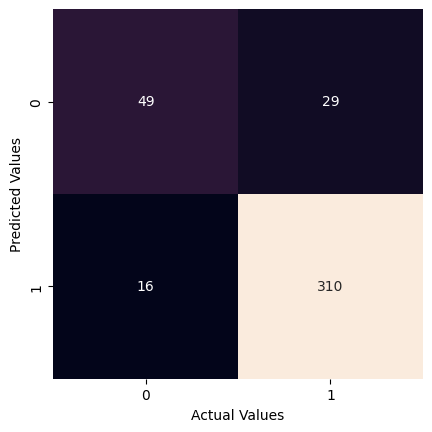

In [ ]:
mat_imp = confusion_matrix(y_test['cancer_type'],y_pred)
sn.heatmap(mat_imp,square=True, annot=True, fmt='d', cbar=False)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

In [ ]:
from sklearn.metrics import roc_curve, auc
y_scores = grid_search.predict_proba(X_test)
fpr, tpr, thresholds = roc_curve(y_test['cancer_type'], y_scores[:, 1])
roc_auc = auc(fpr, tpr)
roc_auc

0.9275994966179016

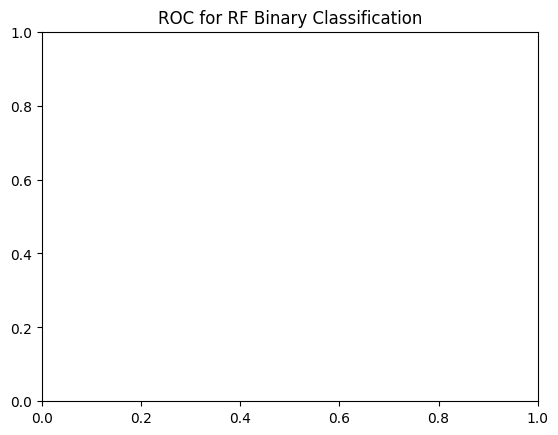

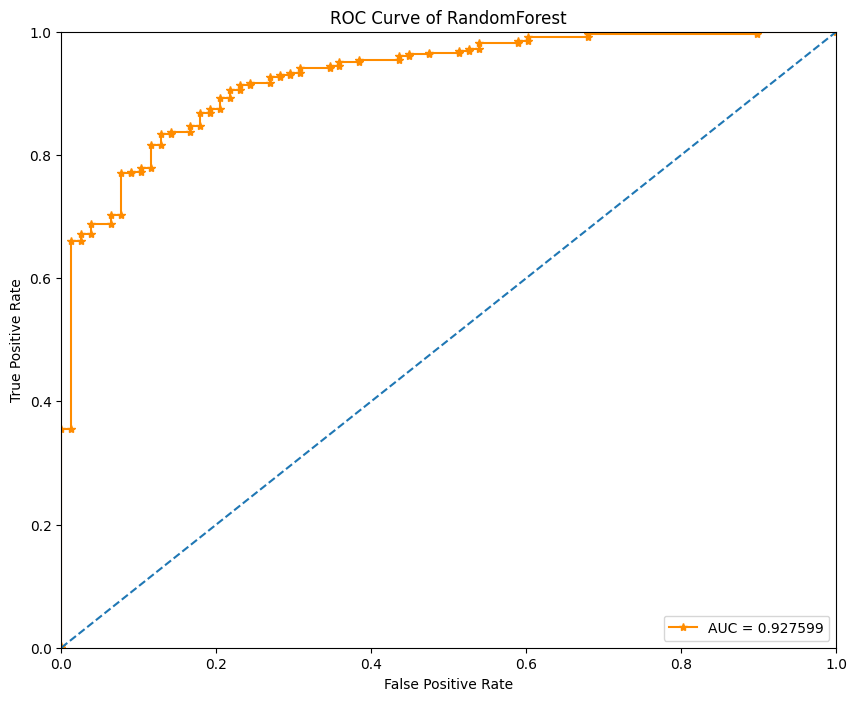

In [ ]:
plt.title('ROC for RF Binary Classification')
plt.figure(figsize=(10,8))
plt.plot(fpr,tpr, marker = '*',color='darkorange',label = 'AUC = %0.6f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('ROC Curve of RandomForest')
plt.show()

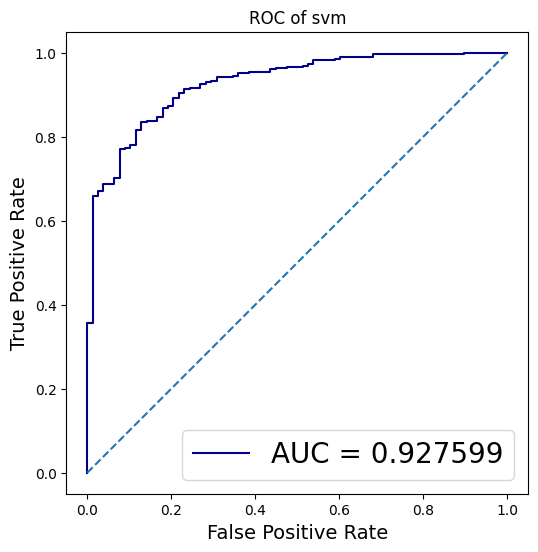

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.title('ROC of svm')
plt.plot(fpr, tpr, color='darkblue', label='AUC = %0.6f' % roc_auc)
plt.legend(loc='lower right', fontsize=20)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.axis('scaled')
plt.ylabel('True Positive Rate', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=14)
plt.show()
